# S03-A2 — Classificação DORA de referência (C1)

A combinação de referência **C1** usa a definição principal de cada métrica:

| Métrica | Coluna do dataset | Elite | High | Medium | Low |
|---|---|---|---|---|---|
| Frequência (releases principais) | `deployment_frequency` | ≥ 7/semana | ≥ 1/semana | ≥ 1 a cada 30 dias | menos |
| Lead time (a), por release | `lead_time_a_horas` | < 1 dia | < 1 semana | < 30 dias | 30 dias ou mais |
| CFR (a), runs de CI | `cfr_a` | ≤ 15% | ≤ 30% | ≤ 45% | mais de 45% |
| Tempo de recuperação | `tempo_recuperacao_horas` | < 1 h | < 1 dia | < 1 semana | 1 semana ou mais |

As faixas e a nota geral vêm de `metricas/classificacao.py` (S01-A4): Elite = 4 … Low = 1, e a
categoria geral é a mediana das quatro notas, arredondada para baixo. A definição principal
**exige as quatro métricas**: um projeto sem alguma delas fica sem categoria geral e é contado,
nunca recebe zero. A coluna `categoria_geral_minimo_3` é só uma análise de sensibilidade.

O cálculo está em `analises/classificacao_c1.py`; `python -m analises.sprint3_a` grava
`data/classificacao_C1.csv` (entrada de C1 para a RQ07) e os resumos em `results/s03_a/`.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd
from IPython.display import Image, display

from analises import classificacao_c1
from analises.entrada import carregar_dataset
from analises.sprint3_a import conferir_publicado

PUBLICADOS = Path("results/s03_a")
pd.set_option("display.width", 160)

df, origens = carregar_dataset()
c1 = classificacao_c1.analisar(df)
conferir_publicado(c1["classificacao_C1"], Path("data/classificacao_C1.csv"))
for nome in ("c1_distribuicao", "c1_ausencias"):
    conferir_publicado(c1[nome], PUBLICADOS / f"{nome}.csv")
print(f"{len(df)} repositórios classificados; dataset {origens['dataset_sha256'][:16]}")
print("Publicados conferidos: data/classificacao_C1.csv, c1_distribuicao.csv, c1_ausencias.csv")

300 repositórios classificados; dataset 8c494ec09f475e7f
Publicados conferidos: data/classificacao_C1.csv, c1_distribuicao.csv, c1_ausencias.csv


## Categoria por métrica e geral

Contagem e porcentagem sobre os 300 projetos. `sem_categoria` reúne os projetos sem a métrica.

In [2]:
d = c1["c1_distribuicao"]
contagem = d.pivot(index="dimensao", columns="categoria", values="n")
porcentagem = d.pivot(index="dimensao", columns="categoria", values="proporcao_total").mul(100).round(1)
ordem_linhas = list(classificacao_c1.DIMENSOES)
ordem_colunas = [*classificacao_c1.CATEGORIAS, classificacao_c1.SEM_CATEGORIA]
contagem.loc[ordem_linhas, ordem_colunas].astype(int).astype(str) + " (" + \
    porcentagem.loc[ordem_linhas, ordem_colunas].astype(str) + "%)"

categoria,Elite,High,Medium,Low,sem_categoria
dimensao,,,,,
deployment_frequency,3 (1.0%),53 (17.7%),122 (40.7%),122 (40.7%),0 (0.0%)
lead_time,57 (19.0%),84 (28.0%),85 (28.3%),74 (24.7%),0 (0.0%)
cfr,235 (78.3%),40 (13.3%),14 (4.7%),11 (3.7%),0 (0.0%)
tempo_recuperacao,85 (28.3%),133 (44.3%),49 (16.3%),11 (3.7%),22 (7.3%)
geral,17 (5.7%),122 (40.7%),110 (36.7%),29 (9.7%),22 (7.3%)
geral_minimo_3,24 (8.0%),128 (42.7%),114 (38.0%),34 (11.3%),0 (0.0%)


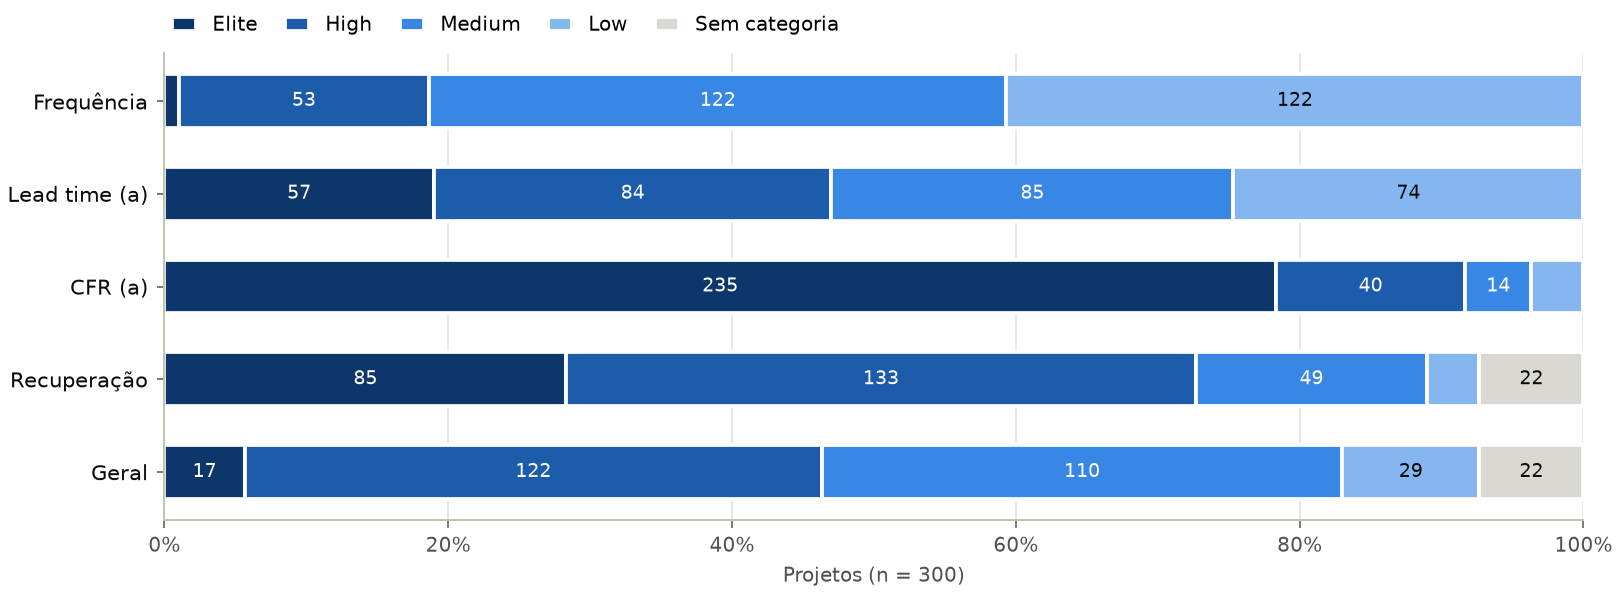

In [3]:
display(Image(filename=str(PUBLICADOS / "c1_distribuicao.png")))

## Projetos sem alguma métrica

Só o tempo de recuperação pode faltar em C1: frequência, lead time (a) e CFR (a) existem para
todos os projetos pelo critério de inclusão (≥ 5 releases e ≥ 50 runs válidos).

In [4]:
c1["c1_ausencias"].groupby(["metrica", "motivo"]).size().rename("projetos")

metrica            motivo       
tempo_recuperacao  sem_episodios    22
Name: projetos, dtype: int64

In [5]:
tabela = c1["classificacao_C1"]
sem_geral = tabela[tabela.categoria_geral.isna()]
print("Categoria que os projetos sem geral teriam com 3 métricas (sensibilidade):")
sem_geral.categoria_geral_minimo_3.value_counts().reindex(classificacao_c1.CATEGORIAS, fill_value=0)

Categoria que os projetos sem geral teriam com 3 métricas (sensibilidade):


categoria_geral_minimo_3
Elite     7
High      6
Medium    4
Low       5
Name: count, dtype: int64

## Proximidade dos limites

Com quatro notas, a mediana é fracionária quando as duas centrais diferem (por exemplo 3 e 2 → 2,5)
e o arredondamento para baixo decide a categoria. Esses projetos são os mais sensíveis a uma
troca de definição operacional, o que interessa à RQ07.

In [6]:
notas = c1["classificacao_C1"].mediana_notas.dropna()
print(f"{(notas % 1 != 0).sum()} de {len(notas)} projetos classificados têm mediana fracionária")
notas.value_counts().sort_index().rename("projetos")

132 de 278 projetos classificados têm mediana fracionária


mediana_notas
1.0     7
1.5    22
2.0    50
2.5    60
3.0    72
3.5    50
4.0    17
Name: projetos, dtype: int64

## Leitura

- A frequência é a dimensão mais fraca: só 3 projetos são Elite e 81% ficam em Medium ou Low,
  coerente com a mediana de 0,33 release por semana da RQ01.
- O CFR (a) é a mais favorável: 78% são Elite, porque menos de 15% dos runs de CI falham na
  maioria dos projetos.
- Lead time (a) se espalha pelas quatro categorias; a recuperação concentra-se em High.
- Na geral, 122 projetos são High e 110 Medium; 17 são Elite e 29 Low. Os 22 sem categoria são
  projetos sem episódio de recuperação observável; com três métricas eles se distribuiriam por todas
  as categorias (7 Elite, 6 High, 4 Medium, 5 Low), então a exclusão não esvazia uma categoria.
- 132 dos 278 classificados (47,5%) dependem do arredondamento da mediana: a categoria geral é
  sensível a mudanças pequenas em uma única métrica.